# Time-resolved stellar activity: M-dwarf flares and chromospheric monitoring

A fiber-combined array reads out once per exposure regardless of the number of telescopes, so
**second-to-minute cadence spectroscopy of bright-ish stars** is a natural niche: H$\alpha$,
H$\beta$ and He I D3 during M-dwarf flares, chromospheric variability of exoplanet hosts, and
accretion variability in young stars (visible lines here; Paschen-$\beta$ with CSHELL in the
NIR notebook).

**Assumptions** (knobs): SNR 20 per resel in the continuum next to H$\alpha$ (650-660 nm) as
the threshold for a usable line profile per exposure; cadences 10 s and 60 s; M dwarfs as
blackbodies of 3300 K normalised in V, with $M_V$ = +10 (M3), +13 (M5) and +16 (M8) for the
distance reach; grey-time sky.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude
try:
    plt.style.use('gks')
except OSError:
    pass

In [2]:
# ---- knobs: array sizes compared throughout (replicated in arrays of 20) ----
SCALES = {20: "nominal 20x (3.2 m eq.)", 200: "10 arrays (10.3 m eq.)", 1720: "86 arrays (30.1 m eq.)"}
NS = np.array([20, 40, 60, 100, 200, 400, 600, 1000, 1720, 2500])
FIG = "../memo/figures/"      # memo figures are saved here as PDF
plt.rcParams.update({"font.size": 11, "axes.titlesize": 10, "legend.fontsize": 9})
def tel(n, telescopes_per_input=20):
    return Telescope(n_telescopes=int(n), fiber="18um", combine="fiber", telescopes_per_input=telescopes_per_input)
def deq(n):
    return 0.726*np.sqrt(n)
from matplotlib.ticker import FixedLocator, FixedFormatter, NullFormatter
def deq_axis(ax):
    """Top axis in equivalent diameter with plain tick labels."""
    sec = ax.secondary_xaxis('top', functions=(deq, lambda d: (d/0.726)**2))
    ticks = [3, 5, 10, 20, 30]
    sec.xaxis.set_major_locator(FixedLocator(ticks)); sec.xaxis.set_major_formatter(FixedFormatter([str(t) for t in ticks]))
    sec.xaxis.set_minor_formatter(NullFormatter()); sec.set_xlabel("Equivalent diameter (m)")
    return sec

In [3]:
WINDOW = (650, 660); SNR_LINE = 20
mdwarf = Source.blackbody(3300, 0, "V")
def bench(n):
    return LFASTETC("bench_r1800", telescope=tel(n))

## Faintest M dwarf with SNR 20 per resel at Halpha, versus cadence and array size

  10 s: N=20: V<14.1  N=200: V<16.2  N=1720: V<17.8
  60 s: N=20: V<16.1  N=200: V<18.1  N=1720: V<19.6
 600 s: N=20: V<18.3  N=200: V<20.1  N=1720: V<21.4


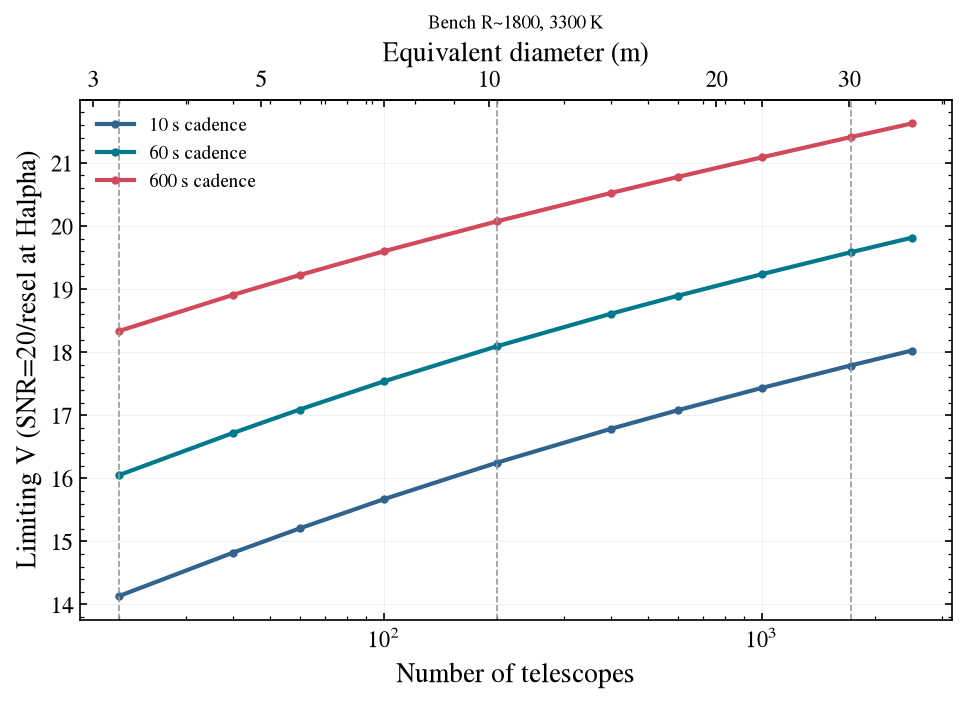

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
lims = {}
for exp, color in ((10, 'C3'), (60, 'C0'), (600, 'C1')):
    d = np.array([bench(int(n)).limiting_magnitude(mdwarf, exp, SNR_LINE, wavelength=WINDOW) for n in NS])
    lims[exp] = dict(zip(NS, d))
    ax.plot(NS, d, marker='o', ms=3, color=color, label=f"{exp} s cadence")
for n in (20, 200, 1720): ax.axvline(n, color='0.6', ls='--', lw=0.8)
ax.set_xscale('log'); ax.set_xlabel("Number of telescopes"); ax.set_ylabel("Limiting V (SNR=20/resel at Halpha)")
ax.set_title("Bench R~1800, 3300 K", fontsize=9); ax.legend()
deq_axis(ax)
fig.savefig(FIG + "flare_cadence_depth_vs_N.pdf")
for exp, d in lims.items():
    print(f"{exp:4d} s: " + "  ".join(f"N={n}: V<{d[n]:.1f}" for n in (20, 200, 1720)))

## Distance reach at 10 s cadence by spectral type

In [5]:
types = {"M3 (M_V=+10)": 10, "M5 (M_V=+13)": 13, "M8 (M_V=+16)": 16}
print(f"{'type':14s}" + "".join(f"{'N=%d' % n:>12s}" for n in (20, 200, 1720)))
for label, MV in types.items():
    row = []
    for n in (20, 200, 1720):
        vlim = lims[10][n]
        row.append(f"{10**((vlim - MV + 5)/5):8.1f} pc")
    print(f"{label:14s}" + "".join(f"{r:>12s}" for r in row))

type                  N=20       N=200      N=1720
M3 (M_V=+10)       67.2 pc    177.8 pc    361.0 pc
M5 (M_V=+13)       16.9 pc     44.7 pc     90.7 pc
M8 (M_V=+16)        4.2 pc     11.2 pc     22.8 pc


## Flare spectra: what a 1-magnitude flare looks like at 10 s cadence

During a large flare the blue continuum brightens by magnitudes while H$\alpha$ goes into
strong emission. A flare is modelled as the quiescent 3300 K star plus a 10,000 K blackbody
component that doubles the V flux (a ~0.75 mag flare), with H$\alpha$ in emission (depth -3 on
a 0.1 nm Gaussian). SNR per resel across the band in 10 s for a V = 12 M dwarf.

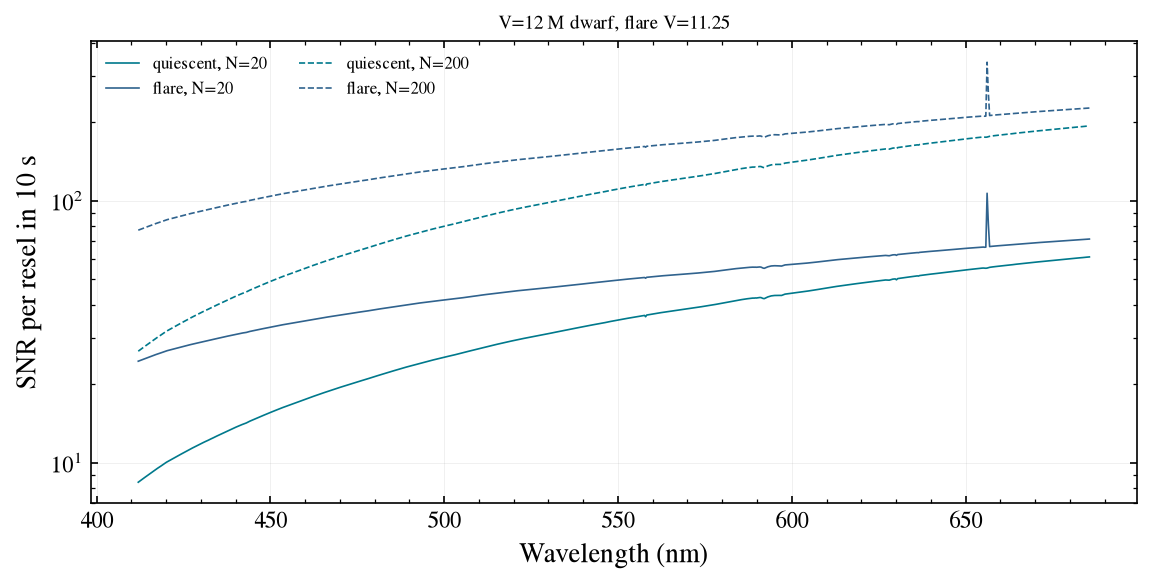

In [6]:
wl = np.linspace(380, 1000, 4000)
quiet = Source.blackbody(3300, 12, "V")
hot = Source.blackbody(10000, 12, "V")
flare_flux = quiet.flux(wl) + hot.flux(wl)
flare = Source.from_arrays(wl, flare_flux, flux_unit="W/m2/nm", band="V").add_line(656.3, -3.0, 0.1)
fig, ax = plt.subplots(figsize=(9, 4))
for n, ls in ((20, '-'), (200, '--')):
    e = bench(n)
    ax.plot(e.wavelength, e.snr(quiet, 10).snr, ls=ls, color='C0', lw=0.8, label=f"quiescent, N={n}")
    ax.plot(e.wavelength, e.snr(flare, 10).snr, ls=ls, color='C3', lw=0.8, label=f"flare, N={n}")
ax.set_yscale('log'); ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("SNR per resel in 10 s")
ax.set_title(f"V=12 M dwarf, flare V={flare.mag:.2f}", fontsize=9); ax.legend(fontsize=8, ncol=2)
fig.savefig(FIG + "flare_snr_10s.pdf")

## Exoplanet-host chromospheric monitoring: Ca II H&K is outside the Bench window, Halpha is not

In [7]:
hosts = {"V=8 K dwarf": (4800, 8), "V=11 M dwarf": (3300, 11), "V=14 M dwarf": (3300, 14)}
for label, (teff, mag) in hosts.items():
    row = []
    for n in (20, 200, 1720):
        r = bench(n).snr(Source.blackbody(teff, mag, "V"), 60)
        row.append(f"N={n}: SNR={r.at(656.3)['snr']:6.0f}" + (" (sat!)" if r.saturated.any() else ""))
    print(f"{label:14s} 60 s at Halpha: " + "  ".join(row))

V=8 K dwarf    60 s at Halpha: N=20: SNR=   706 (sat!)  N=200: SNR=  2233 (sat!)  N=1720: SNR=  6548 (sat!)
V=11 M dwarf   60 s at Halpha: N=20: SNR=   216  N=200: SNR=   682  N=1720: SNR=  2000
V=14 M dwarf   60 s at Halpha: N=20: SNR=    54  N=200: SNR=   170  N=1720: SNR=   499
